# Exercice 1 - Découvrez les blocs de construction de l'Apprentissage par Renforcement

Le but ici, c'est de manipuler un environnement d'apprentissage par renforcement pour la première fois, et de voir tourner le cycle observation, action, récompense.

Il y a deux étapes :

1. Créer l'environnement `CartPole-v1` et regarder ce que l'agent voit et ce qu'il peut faire.
2. Coder un agent qui joue complètement au hasard sur 10 épisodes, et afficher la récompense totale de chaque épisode.

In [ ]:
# Installation des librairies
%pip install -q gymnasium stable-baselines3 matplotlib

In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt

print("Version de Gymnasium :", gym.__version__)

Version de Gymnasium : 1.3.0


## Étape 1 : créer et explorer l'environnement

On crée l'environnement `CartPole-v1` avec `gym.make()`, puis on regarde ses deux attributs principaux :

* `observation_space`, c'est ce que l'agent voit
* `action_space`, c'est ce qu'il peut faire

Sur chacun des deux, la méthode `.sample()` tire un exemple au hasard. Ça permet de voir tout de suite à quoi ils ressemblent.

In [3]:
# Création de l'environnement
env = gym.make("CartPole-v1")
print("Nombre de steps maximum par épisode :", env.spec.max_episode_steps)
print()

# Espace d'observation : ce que l'agent voit
print("Espace d'observation :", env.observation_space)
print("Type                 :", type(env.observation_space).__name__)
print("Dimensions (shape)   :", env.observation_space.shape)
print("Borne basse          :", env.observation_space.low)
print("Borne haute          :", env.observation_space.high)
print()
print("Exemple d'observation aléatoire :", env.observation_space.sample())
print()

# À quoi correspondent les 4 valeurs
noms = ["Position du chariot", "Vitesse du chariot",
        "Angle du bâton", "Vitesse de rotation du bâton"]
for i, nom in enumerate(noms):
    borne_basse = env.observation_space.low[i]
    borne_haute = env.observation_space.high[i]
    print(f"  valeur {i} : {nom:30s} de {borne_basse:>9.3f} à {borne_haute:>8.3f}")

Nombre de steps maximum par épisode : 500

Espace d'observation : Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Type                 : Box
Dimensions (shape)   : (4,)
Borne basse          : [-4.8               -inf -0.41887903        -inf]
Borne haute          : [4.8               inf 0.41887903        inf]

Exemple d'observation aléatoire : [-3.8106806   1.6336426   0.16987407 -0.8304381 ]

  valeur 0 : Position du chariot            de    -4.800 à    4.800
  valeur 1 : Vitesse du chariot             de      -inf à      inf
  valeur 2 : Angle du bâton                 de    -0.419 à    0.419
  valeur 3 : Vitesse de rotation du bâton   de      -inf à      inf


L'espace d'observation est un `Box` de dimension `(4,)`. Une observation, c'est donc juste un tableau de 4 nombres à virgule, et l'affichage ci-dessus donne la correspondance valeur par valeur.

Les deux vitesses n'ont aucune limite, d'où les `inf`. L'angle du bâton est borné à environ 0,419 radian, soit 24 degrés de chaque côté.

C'est tout ce que l'agent connaît du monde : ces 4 nombres.

In [4]:
# Espace d'action : ce que l'agent peut faire
print("Espace d'action  :", env.action_space)
print("Type             :", type(env.action_space).__name__)
print("Nombre d'actions :", env.action_space.n)
print()
print("Exemple d'action aléatoire :", env.action_space.sample())

Espace d'action  : Discrete(2)
Type             : Discrete
Nombre d'actions : 2

Exemple d'action aléatoire : 0


L'espace d'action est un `Discrete(2)`. L'agent n'a que 2 actions possibles, et il n'y a rien entre les deux : `0` pousse le chariot vers la gauche, `1` le pousse vers la droite.

### Point de vigilance

L'observation est un `Box`, donc un espace **continu** : des nombres à virgule. L'action est un `Discrete`, donc un espace **discret** : un choix parmi 2, sans valeur intermédiaire.

C'est une distinction importante pour la suite, parce que c'est elle qui va décider quels algorithmes on pourra utiliser sur cet environnement.

## Étape 2 : implémenter une politique aléatoire

Maintenant l'agent choisit ses actions complètement au hasard, avec `env.action_space.sample()`.

Pour chacun des 10 épisodes :

1. `env.reset()` remet l'environnement à zéro et renvoie la première observation
2. tant que l'épisode n'est ni `terminated` ni `truncated`, on tire une action au hasard et on l'envoie à `env.step()`
3. `env.step()` renvoie 5 valeurs : `observation`, `reward`, `terminated`, `truncated`, `info`
4. on ajoute la `reward` reçue à `total_reward`
5. quand l'épisode est fini, on affiche la récompense totale

Sur `CartPole-v1` la récompense est de +1 à chaque step. Du coup la récompense totale, c'est en fait le nombre de steps pendant lesquels le bâton est resté debout.

In [5]:
n_episodes = 10
recompenses = []

for episode in range(n_episodes):

    # On remet tout à zéro au début de chaque épisode
    observation, info = env.reset()
    total_reward = 0
    terminated = False
    truncated = False

    # Un épisode : on joue jusqu'à ce qu'il se termine
    while not terminated and not truncated:
        action = env.action_space.sample()                                   # action au hasard
        observation, reward, terminated, truncated, info = env.step(action)  # les 5 valeurs
        total_reward += reward

    recompenses.append(total_reward)
    print(f"Épisode {episode + 1:2d} : récompense totale = {total_reward}")

env.close()

Épisode  1 : récompense totale = 16.0
Épisode  2 : récompense totale = 20.0
Épisode  3 : récompense totale = 10.0
Épisode  4 : récompense totale = 24.0
Épisode  5 : récompense totale = 20.0
Épisode  6 : récompense totale = 15.0
Épisode  7 : récompense totale = 12.0
Épisode  8 : récompense totale = 29.0
Épisode  9 : récompense totale = 24.0
Épisode 10 : récompense totale = 28.0


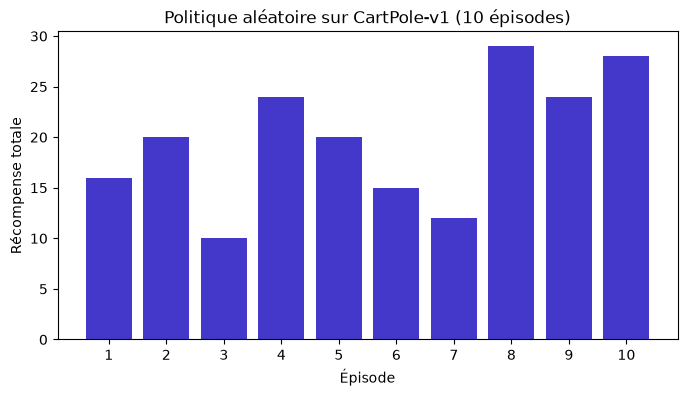

In [6]:
plt.figure(figsize=(8, 4))
plt.bar(range(1, n_episodes + 1), recompenses, color="#4338CA")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")
plt.title("Politique aléatoire sur CartPole-v1 (10 épisodes)")
plt.xticks(range(1, n_episodes + 1))
plt.show()

## Ce qu'on observe

Les récompenses sont faibles, et elles changent beaucoup d'un épisode à l'autre. Sur seulement 10 épisodes, la moyenne peut aussi bien tomber à 15 qu'à 30 : c'est le hasard.

Sauf qu'un épisode peut durer jusqu'à 500 steps, comme l'a montré le `max_episode_steps` affiché à l'étape 1. Un agent qui joue au hasard n'en atteint jamais que quelques dizaines, parce qu'il fait tomber le bâton bien avant.

C'est le point de départ du problème : l'agent n'a que ce score pour se guider, rien ne lui dit quelle action était la bonne. Tout le travail ensuite va consister à faire monter ce chiffre.